In [36]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [37]:
# Load the dataset
df = pd.read_excel("/content/Customers.xlsx")

In [38]:
print (df)

       Age  Income Student Credit_rating Buy_computer
0    young    high      no          fair           no
1    young    high      no     excellent           no
2   middle    high      no          fair          yes
3      old  medium      no          fair          yes
4      old     low     yes          fair          yes
5      old     low     yes     excellent           no
6   middle     low     yes     excellent          yes
7    young  medium      no          fair           no
8    young     low     yes          fair          yes
9      old  medium     yes          fair          yes
10   young  medium     yes     excellent          yes
11  middle  medium      no     excellent          yes
12  middle    high     yes          fair          yes
13     old  medium      no     excellent           no


In [39]:
# Check for missing values in each column
df.isnull().sum()

,0
Age,0
Income,0
Student,0
Credit_rating,0
Buy_computer,0


In [42]:
# Drop rows with any missing values
df = df.dropna()

In [43]:
# Find duplicate rows
duplicates = df[df.duplicated()]
print(duplicates)

Empty DataFrame
Columns: [Age, Income, Student, Credit_rating, Buy_computer]
Index: []


In [44]:
# Remove duplicate rows
df = df.drop_duplicates()

In [45]:
# Encode categorical variables using LabelEncoder
encoder = LabelEncoder()
encoded_df = df.apply(encoder.fit_transform)

In [46]:
# Separate features and target variable
X = encoded_df.drop(columns=['Buy_computer'])
y = encoded_df['Buy_computer']

In [47]:
# Step 3: Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [59]:
# Step 4: Train a Decision Tree Classifier
classifier = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
classifier.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [55]:
# Step 5: Visualize the decision tree structure (Textual format)
tree_rules = export_text(classifier, feature_names=list(X.columns))
print("Decision Tree Rules:")
print(tree_rules)

Decision Tree Rules:
|--- Credit_rating <= 0.50
|   |--- Student <= 0.50
|   |   |--- class: 0
|   |--- Student >  0.50
|   |   |--- class: 1
|--- Credit_rating >  0.50
|   |--- class: 1



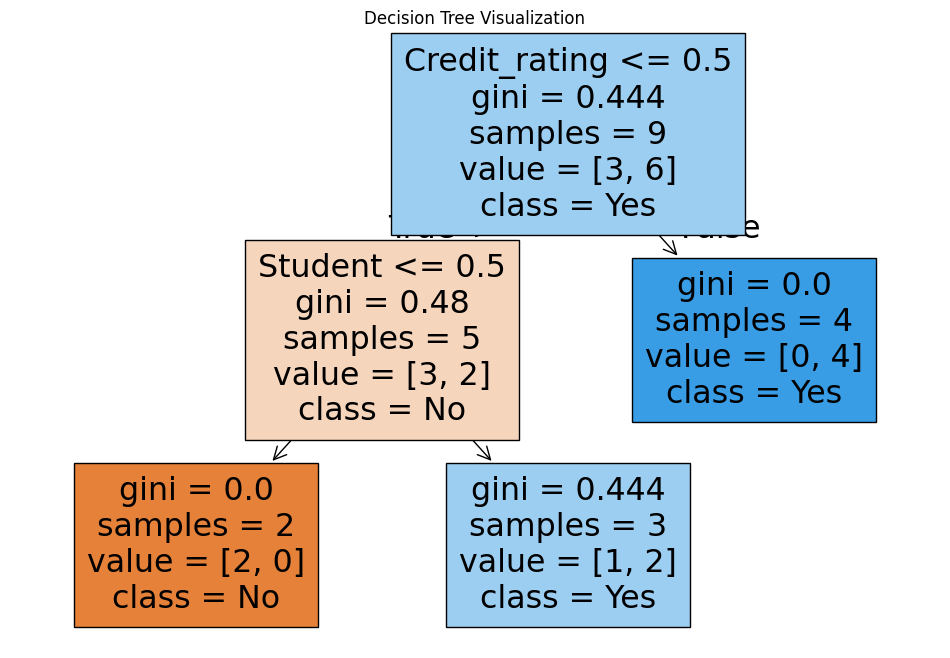

In [56]:
plt.figure(figsize=(12, 8))
plot_tree(classifier, feature_names=X.columns, class_names=['No', 'Yes'], filled=True)
plt.title("Decision Tree Visualization")
plt.show()

In [57]:
y_pred = classifier.predict(X_test)

In [58]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy of the Decision Tree Classifier: {accuracy * 100:.2f}%")

Accuracy of the Decision Tree Classifier: 40.00%


In [53]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['No', 'Yes']))

Confusion Matrix:
[[0 2]
 [1 2]]

Classification Report:
              precision    recall  f1-score   support

          No       0.00      0.00      0.00         2
         Yes       0.50      0.67      0.57         3

    accuracy                           0.40         5
   macro avg       0.25      0.33      0.29         5
weighted avg       0.30      0.40      0.34         5

